# Import a paired Run/Ch/Cy SPR export

Import **`paired_run.csv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses the small file committed with the repository;
it does not download data or fit a model.

**Data origin:** [rstoolbox example03/spr_data.txt](https://github.com/lpdi-epfl/rstoolbox/blob/2bfc9be5ec6111603fb78700f201b80331ef0132/notebook/data/example03/spr_data.txt). Copyright (c) 2017 Jaume Bonet, MIT license.
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](../test_files/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/rstoolbox-LICENSE).

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

# Works from the repository root, notebooks/, or docs/notebooks/.
cwd = Path.cwd().resolve()
repo_root = next(
    path for path in (cwd, *cwd.parents)
    if (path / "src" / "pykingenie").is_dir()
    and (path / "test_files" / "spr_exports").is_dir()
)
sys.path.insert(0, str(repo_root / "src"))
from pykingenie import SprTextExperiment, KineticsAnalyzer, plot_plate_info

plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
data_file = repo_root / "test_files" / "spr_exports" / "paired_run.csv"
print("Input:", data_file.name)

Input: paired_run.csv


## File layout and import settings

One named `_X` time column and `_Y` response column per curve. This sparse excerpt contains two measured curves and one exported fitted curve. The reader excludes the fitted curve.

These text exports do not establish injection-event timing. The boundaries
below are **illustrative API settings**, not verified experimental events.
Replace them with your experiment's actual boundaries before kinetic analysis.
Both boundaries are seconds on the exported time axis. Association uses
`[association_start, association_end)`; dissociation starts at `association_end`.
There may be no baseline points before `association_start`.

The `conc=0.0585` and `conc=0.117` labels have no verified unit. They stay as labels; the concentration table remains `NaN`. No instrument identity or response unit is assumed from this file.

The expected concentration warning is displayed explicitly below. The common
`sample_id="unassigned"` is a grouping placeholder, not a biological identity
recovered from the file.

In [2]:
association_start = 0.0   # illustrative; replace with actual timing
association_end = 300.0  # illustrative; replace with actual timing

experiment = SprTextExperiment("paired_run")
with warnings.catch_warnings(record=True) as messages:
    warnings.simplefilter("always", UserWarning)
    experiment.read_file(
        data_file,
        association_start=association_start,
        association_end=association_end,
        decimal='.',
        time_unit="s",
        sample_id="unassigned",
    )
for message in messages:
    print(message.message)
print(f"Imported {experiment.no_sensors} measured curves; {experiment.no_steps} API phases.")
assert experiment.traces_loaded and experiment.no_sensors == 2

Some analyte concentrations are unavailable or have no unit. Provide concentrations or edit ligand_conc_df before fitting.
Imported 2 measured curves; 3 API phases.


## Available curve information

Each measured curve becomes a sensor in the experiment object. Its complete
original label remains in `sensor_names`. The following table extracts only
the header/row-label fields present in this specific example file.

In [3]:
curve_ids = [f"Curve {i + 1}" for i in range(experiment.no_sensors)]
labels = pd.Series(experiment.sensor_names, name="Exported label")
header_info = labels.str.extract('Run\\s+(?P<Run>\\d+);\\s*Ch\\s+(?P<Channel>\\d+);\\s*Cy\\s+(?P<Cycle>\\d+);.*conc=(?P<Concentration_label>.+)$')
header_info.insert(0, "Curve", curve_ids)
display(header_info)
display(labels.to_frame())

,Curve,Run,Channel,Cycle,Concentration_label
0,Curve 1,1,1,6,0.0585
1,Curve 2,1,1,7,0.117


,Exported label
0,Run 1; Ch 1; Cy 6; RefSub; 1kx8_d02; conc=0.0585
1,Run 1; Ch 1; Cy 7; RefSub; 1kx8_d02; conc=0.117


## Concentration metadata

`NaN` means a molar concentration is unavailable, not zero concentration.
Before fitting, supply your verified values through `concentrations` and
`concentration_unit` at import, or update `ligand_conc_df`. A list follows the
measured-curve order; a mapping can use full exported curve labels as keys.

In [4]:
concentration_info = experiment.ligand_conc_df.copy()
concentration_info.insert(0, "Curve", curve_ids)
display(concentration_info[["Curve", "Concentration_micromolar", "SampleID"]])
assert concentration_info["Concentration_micromolar"].isna().all()

,Curve,Concentration_micromolar,SampleID
0,Curve 1,NaN,unassigned
1,Curve 2,NaN,unassigned


## Plate information, when available

Run, channel and cycle numbers identify acquisitions, not sample-plate wells. No row/column coordinates are present.

The conditional cell below uses `plot_plate_info` only when the experiment
actually contains the required plate metadata. It prints a message for this
file rather than assigning artificial well positions.

In [5]:
analyzer = KineticsAnalyzer()
analyzer.add_experiment(experiment, experiment.name)
plate_fields = (
    "sample_row", "sample_column", "sample_type", "sample_id", "sample_conc_labeled"
)
have_plate_info = all(
    getattr(experiment, field) is not None
    and len(getattr(experiment, field)) > 0
    for field in plate_fields
)
if have_plate_info:
    display(pd.DataFrame({field: getattr(experiment, field) for field in plate_fields}))
    plot_plate_info(analyzer, experiment.name).show()
else:
    print("No plate-well coordinates are available in this export; no plate plot is created.")

No plate-well coordinates are available in this export; no plate plot is created.


## Imported sensorgrams

Join the API phases back together for plotting on each curve's original time
grid. No time alignment or signal correction is applied. Markers show the
retained observations; short legend labels refer to the tables above.

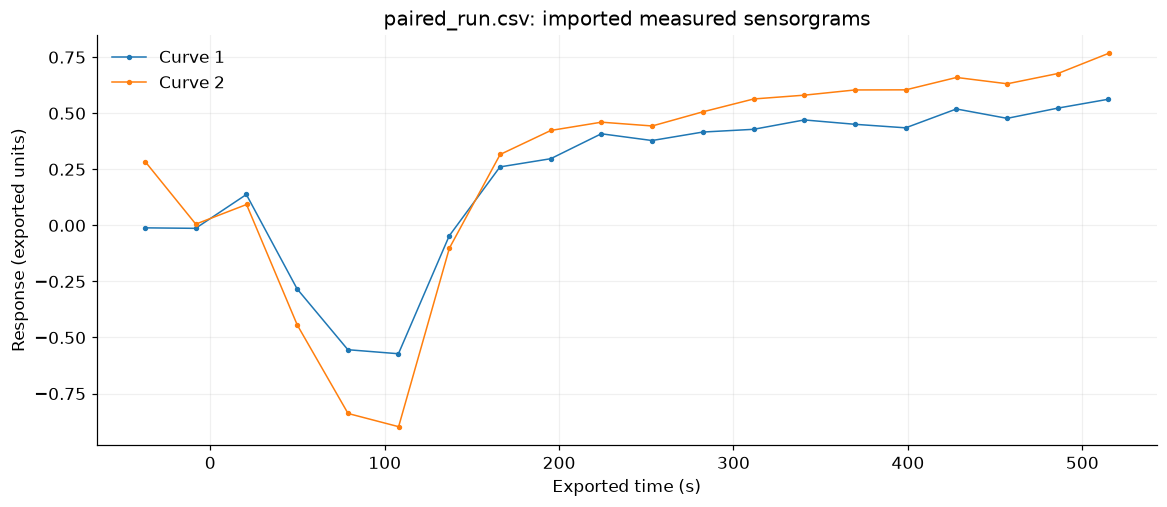

In [6]:
fig, ax = plt.subplots(figsize=(10.5, 4.5), constrained_layout=True)
for i, curve in enumerate(curve_ids):
    time = np.concatenate(experiment.xs[i])
    response = np.concatenate(experiment.ys[i])
    ax.plot(time, response, "o-", markersize=2.5, linewidth=1, label=curve)
ax.set(title="paired_run.csv: imported measured sensorgrams",
       xlabel="Exported time (s)", ylabel="Response (exported units)")
ax.legend(frameon=False)
ax.grid(alpha=0.18)
plt.show()

## Check the retained points and API partitions

The original times remain in `xs`; `ys` contains the corresponding measured
responses. The phase counts below reflect the illustrative boundaries above,
not injection events detected from the signal.

In [7]:
imported_points = pd.DataFrame([
    {
        "Curve": curve_ids[i],
        "Baseline points": len(experiment.xs[i][0]),
        "Association points": len(experiment.xs[i][1]),
        "Dissociation points": len(experiment.xs[i][2]),
        "Total points": sum(len(step) for step in experiment.xs[i]),
        "First exported time (s)": np.concatenate(experiment.xs[i])[0],
        "Last exported time (s)": np.concatenate(experiment.xs[i])[-1],
    }
    for i in range(experiment.no_sensors)
])
display(imported_points)
display(experiment.df_steps[["Name", "Type", "Start"]])

,Curve,Baseline points,Association points,Dissociation points,Total points,First exported time (s),Last exported time (s)
0,Curve 1,2,10,8,20,-37.400002,515.000000
1,Curve 2,2,10,8,20,-37.300003,515.099976


,Name,Type,Start
0,Baseline,BASELINE,-37.400002
1,Association,ASSOC,0.000000
2,Dissociation,DISASSOC,300.000000


The full upstream file contains 539 partial pairs with `NaN` responses and is rejected by the current strict reader. This retained sparse excerpt has complete measurements. See the [reference comparisons](../validation/spr_parsers/README.md) for the explicit complete-observation comparison. The excerpt is not suitable for estimating kinetic parameters.